# Lesson 1 · The task and the physics

This is the first of four lessons that walk through this repo from the ground up. Run
the cells top to bottom (Shift-Enter). Nothing in this lesson trains a network. By the
end you should be able to say exactly **what the agent controls, what a trial is, and
what the agent sees**.

| lesson | what you will understand |
|---|---|
| **1 · task and physics** (this one) | the config, the point mass, a trial, the observation |
| 2 · reward | every reward term, what it is worth, how to change it, and why the task lets lookahead pay |
| 3 · agent and training | the network, what PPO does, its losses, how to read a training log |
| 4 · measuring an agent | the competence gate, the co-articulation index, running your own experiments |

Each section follows the same pattern: **the idea** in words, then a short cell to **see
it**, then **where it lives** in the code and which **knobs** change it. Each lesson ends
with a few questions; the answers are folded underneath them.

## 0 · The repo in one picture

```
 seqreach/config.py           seqreach/env.py                    seqreach/networks.py
 ┌────────────────┐        ┌───────────────────────┐           ┌──────────────────────┐
 │ Config         │ ─────► │ environment            │ ◄──────► │ agent (GRU network)  │
 │ every knob     │        │ physics + trial +      │  force    │ observation → force  │
 └────────────────┘        │ reward                 │ ◄──────── │                      │
                           └───────────────────────┘ obs,reward└──────────────────────┘
                                         │                                  ▲
                                         ▼                                  │
                           seqreach/ppo.py: PPO training loop ──────────────┘ updates weights
                                         │
                                         ▼
                       runs/<name>_s<seed>/checkpoint.pt   (a trained agent)
                                         │
                                         ▼
          seqreach/probes.py + metrics.py  (scripts/analyze.py): experiments on the frozen agent
```

**The question the repo asks.** People reaching through a sequence of targets shape the
first reach according to where the *next* target is (co-articulation, or lookahead). Here
a point mass on a line is trained with reinforcement learning to hit 1–3 targets in order.
Nothing in its reward mentions trajectories or the next target. The question is whether
lookahead appears anyway, and which parts of the task it depends on.

Start by importing. `lesson_tools` is a small helper file next to this notebook: it puts
`1D/` on Python's import path and holds a plot style and a few helpers. It is not research
code.

In [2]:
from lesson_tools import *   # 1D/ on the import path, plot style, small helpers
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from seqreach.config import Config
from seqreach.env import BatchedSeqReach1D

use_style()

## 1 · The config: every knob in one object

**The idea.** Everything you can change lives in a single `Config` object. It is split into
sections: `plant` (the physics), `task` (how trials are built), `reward`, `agent` (the
network), `ppo` (the learning algorithm), plus `video` and `wandb` for bookkeeping. A
training run is one config plus one random seed.

**Where it lives:** [`seqreach/config.py`](../seqreach/config.py). Every field there has a
default value and usually a comment explaining it.

In [3]:
cfg = Config()
list(vars(cfg))          # the top-level fields and sections

['exp_name',
 'seed',
 'torch_threads',
 'plant',
 'task',
 'reward',
 'agent',
 'ppo',
 'video',
 'wandb']

In [4]:
show(cfg.plant)          # one section as a table

,value
key,
dt,0.02
mass,1.00
damping,0.20
u_max,8.00
tau_act,0.05
sigma_sdn,0.05
sigma_add,0.00
sensory_delay,0.00
x_limit,1.50


To change something, **don't edit the file**. Make a modified copy with `override`, using
dotted names (`section.key`). The original is left untouched.

In [5]:
cfg2 = cfg.override({"plant.tau_act": 0.1, "reward.w_effort": 0.0})
print("modified copy:", cfg2.plant.tau_act, cfg2.reward.w_effort)
print("original:     ", cfg.plant.tau_act, cfg.reward.w_effort)

modified copy: 0.1 0.0
original:      0.05 0.5


A typo raises an error instead of silently doing nothing. This matters: a misspelled key
that was silently ignored would give you a run that differs from what you think it is.

In [6]:
try:
    cfg.override({"reward.w_efort": 0.0})      # misspelled on purpose
except KeyError as err:
    print("KeyError:", err)

KeyError: "unknown config key 'reward.w_efort'"


The command-line scripts take the same dotted names:

```bash
python 1D/scripts/train.py --name my_run --set reward.w_effort=0 plant.tau_act=0.1
```

Every run saves its full config next to its checkpoint, so you can always check what a
run actually used:

In [7]:
saved = Config.load(RUNS / "baseline_s1" / "config.yaml")
saved.exp_name, saved.seed, saved.task.max_steps, saved.ppo.total_timesteps

('baseline', 1, 600, 3000000)

## 2 · The plant: what the agent is pushing

**The idea.** The body is a point mass on a line. Every 20 ms (`dt = 0.02`) the agent
chooses one number, a force `u` between −8 and +8. Everything else follows from physics:

```
a ← a + (dt/τ)·(u − a)        activation: force builds up with a lag, τ = 50 ms (muscle-like)
v ← v + dt·(a − b·v) / m      Newton's law, with a little damping b = 0.2, mass m = 1
x ← x + dt·v                  position
```

So the agent sits at the top of a chain: force → activation → velocity → position. To be
at a given place at a given speed, it has to commit force **in advance**.

**See it.** Apply a hand-made force sequence and watch the chain respond. The function
below builds a one-trial environment, then calls `env.step(force)` once per 20 ms.

In [8]:
def simulate(cfg, command):
    '''Apply a fixed sequence of forces to the point mass and record what happens.'''
    env = BatchedSeqReach1D(cfg, num_envs=1, seed=0)
    # One far-away target and no hold period, so the trial neither ends nor penalises us.
    env.reset({"n_targets": [1], "targets": [[0.9, 0, 0]], "preview": [1], "delay_steps": [0]})
    rows = []
    for u in command:
        env.step(np.array([u]))
        rows.append({"time_s": env.t[0] * cfg.plant.dt, "u": u,
                     "a": env.a[0], "v": env.v[0], "x": env.x[0]})
    return pd.DataFrame(rows)

quiet = Config().override({"plant.sigma_sdn": 0.0})      # motor noise off for now
command = np.r_[np.full(10, 8.0), np.full(10, -8.0), np.zeros(20)]   # push 0.2 s, brake 0.2 s, let go
push = simulate(quiet, command)
push.head()


,time_s,u,a,v,x
0,0.02,8.0,3.20000,0.064000,0.001280
1,0.04,8.0,5.12000,0.166144,0.004603
2,0.06,8.0,6.27200,0.290919,0.010421
3,0.08,8.0,6.96320,0.429020,0.019002
4,0.10,8.0,7.37792,0.574862,0.030499


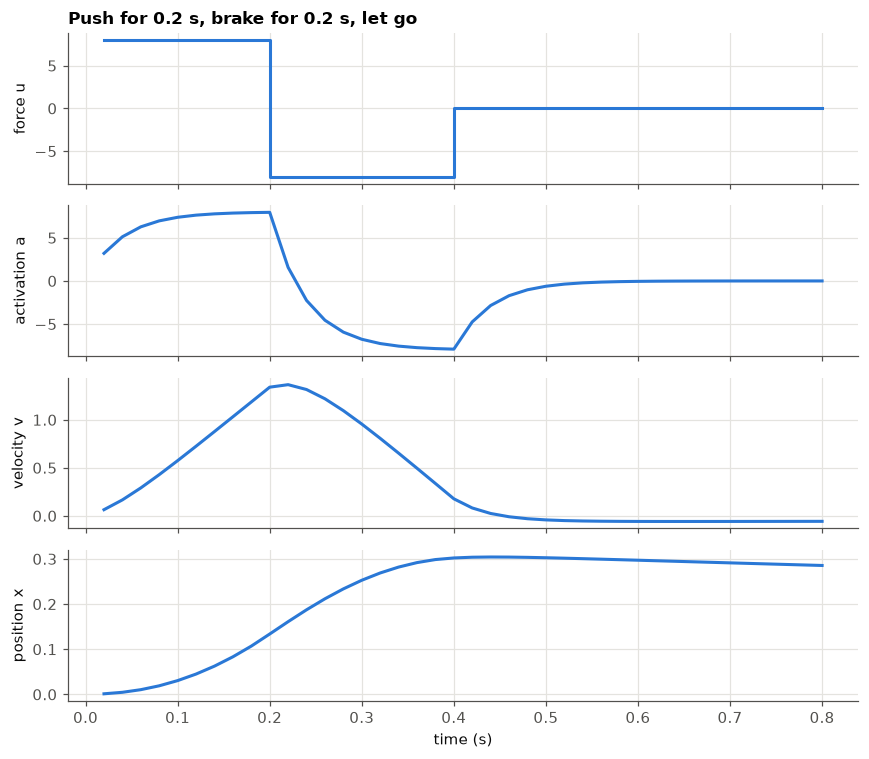

In [9]:
fig, axes = plt.subplots(4, 1, figsize=(8, 7), sharex=True)
for ax, col, label in zip(axes, ["u", "a", "v", "x"],
                          ["force u", "activation a", "velocity v", "position x"]):
    ax.plot(push.time_s, push[col], color=BLUE, drawstyle="steps-pre" if col == "u" else "default")
    ax.set_ylabel(label)
axes[0].set_title("Push for 0.2 s, brake for 0.2 s, let go")
axes[-1].set_xlabel("time (s)")
plt.tight_layout()

**Reading it.** The activation lags the force command by a few tens of milliseconds.
Velocity is the running sum of activation, and position is the running sum of velocity.
After the brake the mass nearly stops, but not exactly, because the brake was timed by
hand. A trained agent has to learn that timing.

**The activation lag** is what makes momentum a resource you must plan for. Here is the
same command with three different lags:

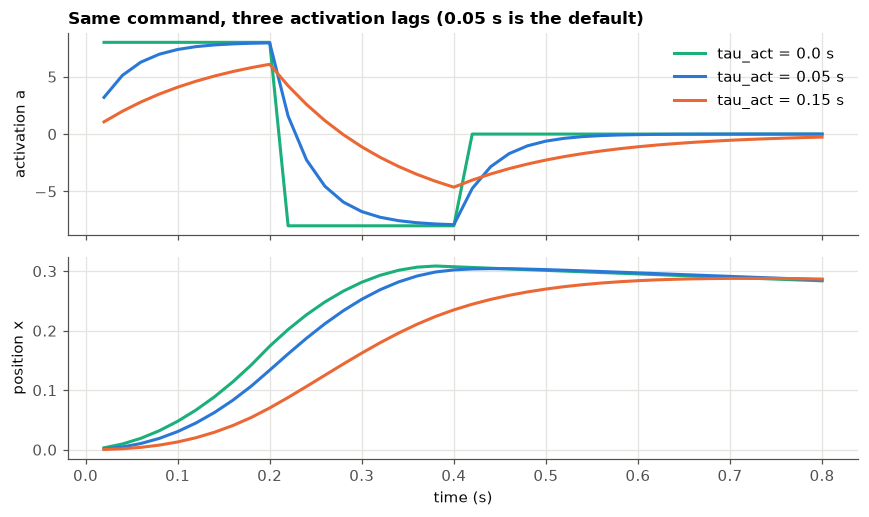

In [10]:
fig, (ax_a, ax_x) = plt.subplots(2, 1, figsize=(8, 4.8), sharex=True)
for tau, color in zip([0.0, 0.05, 0.15], [AQUA, BLUE, ORANGE]):
    run = simulate(quiet.override({"plant.tau_act": tau}), command)
    ax_a.plot(run.time_s, run.a, color=color, label=f"tau_act = {tau} s")
    ax_x.plot(run.time_s, run.x, color=color)
ax_a.set_ylabel("activation a")
ax_x.set_ylabel("position x")
ax_x.set_xlabel("time (s)")
ax_a.set_title("Same command, three activation lags (0.05 s is the default)")
ax_a.legend(loc="upper right")
plt.tight_layout()

**Motor noise.** Real motor commands are noisy, and the noise grows with the size of the
command (signal-dependent noise, as in Harris & Wolpert). Here that is `sigma_sdn`: each
step, the activation is jittered by `sigma_sdn × |a| × (random normal)`.

This is also the moment to see that the environment is **batched**. `num_envs=20` runs 20
independent trials in lockstep: `env.x` holds 20 numbers, and `env.step` takes 20
forces. Training runs 32 trials at once this way, and the analysis runs hundreds.

sigma_sdn = 0.05:  end-point SD  strong 0.0137   gentle 0.0069
sigma_sdn = 0.3:  end-point SD  strong 0.0823   gentle 0.0411


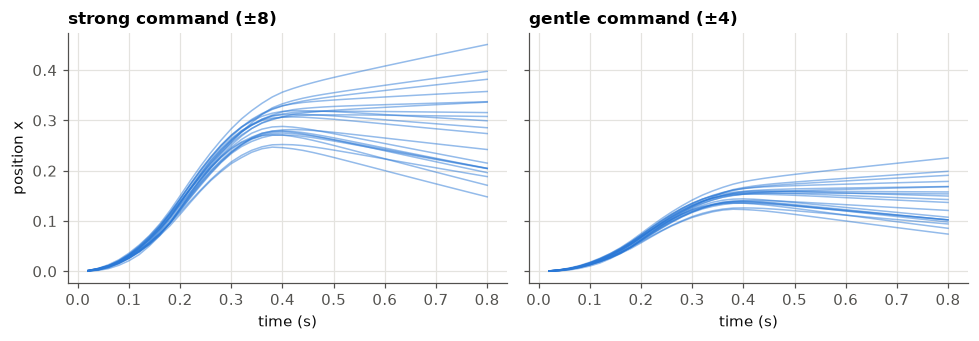

In [11]:
def simulate_many(cfg, command, n=20):
    env = BatchedSeqReach1D(cfg, num_envs=n, seed=0)
    env.reset({"n_targets": [1], "targets": [[0.9, 0, 0]], "preview": [1], "delay_steps": [0]})
    xs = []
    for u in command:
        env.step(np.full(n, u))          # one force per trial
        xs.append(env.x.copy())          # one position per trial
    return np.array(xs)                  # shape (time, trial)

strong = np.r_[np.full(10, 8.0), np.full(10, -8.0), np.zeros(20)]
gentle = np.r_[np.full(10, 4.0), np.full(10, -4.0), np.zeros(20)]
t = np.arange(1, len(strong) + 1) * 0.02

loud = Config().override({"plant.sigma_sdn": 0.3})      # 6x the default so the spread is visible
fig, axes = plt.subplots(1, 2, figsize=(9, 3.2), sharey=True)
for ax, cmd, title in zip(axes, [strong, gentle], ["strong command (±8)", "gentle command (±4)"]):
    ax.plot(t, simulate_many(loud, cmd), color=BLUE, lw=1, alpha=0.5)
    ax.set_title(title)
    ax.set_xlabel("time (s)")
axes[0].set_ylabel("position x")
plt.tight_layout()

for sigma in [0.05, 0.3]:
    c = Config().override({"plant.sigma_sdn": sigma})
    print(f"sigma_sdn = {sigma}:  end-point SD  strong {simulate_many(c, strong)[-1].std():.4f}"
          f"   gentle {simulate_many(c, gentle)[-1].std():.4f}")

Bigger commands give more variable movements. At the default `sigma_sdn = 0.05` the
spread is small compared with the target size (±0.05), but it is not zero. The analysis
switches noise **off** so that measurements are exactly reproducible (lesson 4).

**Where it lives:** `BatchedSeqReach1D.step` in [`seqreach/env.py`](../seqreach/env.py),
the block commented `# --- plant`.

**Knobs (`plant.*`):**

| key | default | meaning |
|---|---|---|
| `dt` | 0.02 | seconds per simulation step (one decision every 20 ms) |
| `mass`, `damping` | 1.0, 0.2 | the point mass |
| `u_max` | 8.0 | maximum force; commands are clipped to ±u_max |
| `tau_act` | 0.05 | activation lag in seconds; 0 = force acts instantly |
| `sigma_sdn` | 0.05 | signal-dependent motor noise |
| `sigma_add` | 0.0 | constant (additive) motor noise |
| `sensory_delay` | 0 | steps of delay in the x, v the agent observes |
| `x_limit` | 1.5 | workspace wall. Touching it stops the mass and costs reward (lesson 2); targets never go past ±0.9 |

## 3 · A trial

**The idea.** A trial is one attempt at a sequence of targets:

```
   targets shown           go cue             reach T1 → T2 → …              final target
   ├── HOLD near x = 0 ────┤──────────────────────────────────────────────┤ held 0.3 s ├ end
   t = 0          random, roughly 0.25–1.0 s (the agent cannot predict it)
```

The rules:

- **1 to 3 targets**, each somewhere in ±0.9, acquired **in order**.
- **Hold:** until the go cue, stay near the start. Leaving |x| > 0.15 is a **false start**:
  −5 reward, and the trial ends.
- **Acquire:** after the go cue, a target counts as hit when x is within ±0.05 of it
  (`tolerance`) for enough consecutive steps. That is **1 step for intermediate
  targets** (`dwell_inter = 1`, so passing through is enough) and **15 steps = 0.3 s for
  the last target** (`dwell_final`).
- **End:** the trial ends on success (last target held), on a false start, or at
  `max_steps = 600` (12 s, a timeout).

**See it.** Below is a whole trial driven by a *hand-written* controller, not a learned
one. After the go cue it acts like a spring and damper pulling toward the current target.
The loop is the most important thing in this lesson: it is exactly how the training loop
and the analysis talk to the environment.

In [12]:
cfg = Config().override({"plant.sigma_sdn": 0.0})
env = BatchedSeqReach1D(cfg, num_envs=1, seed=0)

# A "spec" pins down the trial instead of sampling it at random.
obs = env.reset({"n_targets": [2], "targets": [[0.5, -0.3, 0.0]],
                 "preview": [2], "delay_steps": [25]})

kp, kd = 60.0, 14.0                                  # spring and damper strength
for step in range(cfg.task.max_steps):
    go = env.t[0] >= env.go_step[0]                  # has the go cue fired?
    target = env.targets[0, env.cur[0]]              # the target currently being reached for
    u = kp * (target - env.x[0]) - kd * env.v[0] if go else 0.0

    obs, reward, terminated, truncated, info = env.step(np.array([u]))

    if terminated[0] or truncated[0]:
        summary = {k: v[0].item() for k, v in info["episode"].items()}
        print(f"trial over after {step + 1} steps:\n{summary}")
        break

trial over after 100 steps:
{'r': 28.15181747390761, 'r_task': 27.92756845338938, 'l': 100, 'hits': 2, 'wall_steps': 0, 'n_targets': 2, 'success': True, 'false_start': False, 'timeout': False, 'cur': 2}


What `env.step(force)` hands back:

| returned | meaning |
|---|---|
| `obs` | what the agent sees next (section 4) |
| `reward` | reward for this step (lesson 2) |
| `terminated` | the trial ended for a real reason: success or false start |
| `truncated` | the trial ran out of time (`max_steps`) |
| `info` | at the end of a trial, `info["episode"]` summarises it: total reward `r`, reward without shaping `r_task`, length `l`, targets hit, success, and so on |

One subtlety: when a trial ends, the environment **immediately starts a new one** in the
same call (this is called autoreset). So after the last step, `env.x` already belongs to
the next trial, and the finished trial's final values are in `info`.

The helper `run_trial` in `lesson_tools.py` is the same loop, packaged. It returns one
table row per step, which the later cells plot. The controller is passed in as a
function.

In [13]:
df, episode = run_trial(cfg, targets=[0.5, -0.3], controller=pd_controller())
df.head(3)

,step,time_s,go,u,a,v,x,target_now,cur,acquired,reward
0,0,0.00,False,0.0,0.0,0.0,0.0,0.5,0,False,0.0
1,1,0.02,False,0.0,0.0,0.0,0.0,0.5,0,False,0.0
2,2,0.04,False,0.0,0.0,0.0,0.0,0.5,0,False,0.0


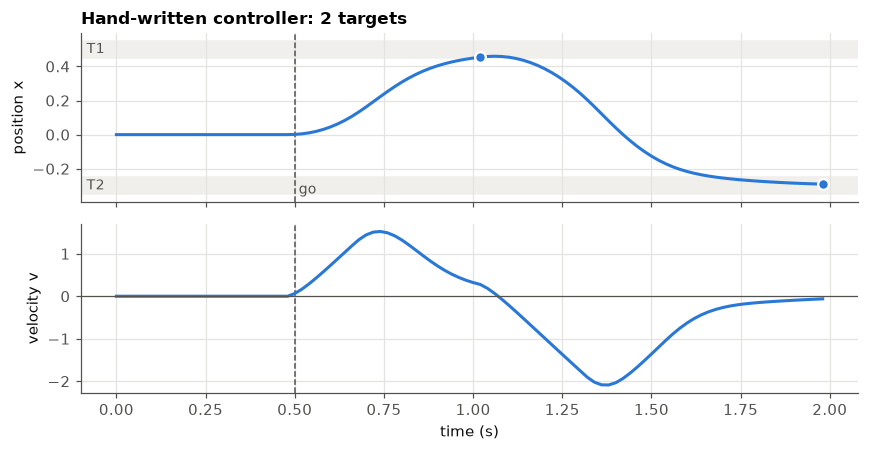

In [14]:
plot_trial(df, [0.5, -0.3], cfg, title="Hand-written controller: 2 targets")
plt.tight_layout()

The dashed line is the go cue, the grey bands are the targets (±tolerance), and the dots
mark acquisitions. This controller **aims to stop at every target**. It is still
slowing down when it enters T1's band, and it turns toward T2 only once T1 counts as hit,
because it has no idea a next target exists. Lesson 2 compares it with one that plans
for T2.

Three targets, and a controller that ignores the go cue:

impatient controller: {'l': 11, 'false_start': True, 'success': False, 'r': -23.417585232087603}


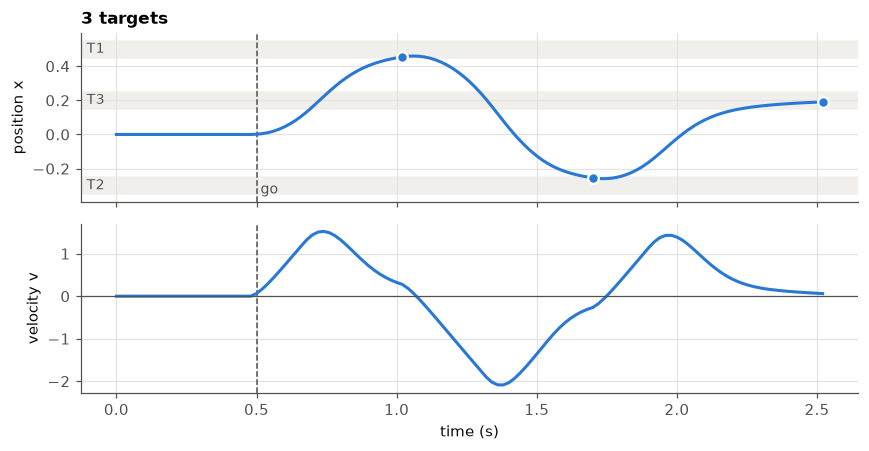

In [15]:
df3, ep3 = run_trial(cfg, [0.5, -0.3, 0.2], pd_controller())
plot_trial(df3, [0.5, -0.3, 0.2], cfg, title="3 targets")
plt.tight_layout()

impatient = lambda state: 8.0                      # full force from the very first step
_, ep = run_trial(cfg, [0.5, -0.3], impatient)
print("impatient controller:", {k: ep[k] for k in ("l", "false_start", "success", "r")})

**Where it lives:** trials are built in `_sample_trials` and the rules are applied in `step`,
both in [`seqreach/env.py`](../seqreach/env.py).

**Knobs (`task.*`):**

| key | default | meaning |
|---|---|---|
| `max_targets` | 3 | targets per trial at most |
| `n_target_weights` | (0.2, 0.3, 0.5) | how often trials have 1, 2, 3 targets |
| `target_range`, `min_separation` | 0.9, 0.15 | targets lie in ±0.9, at least 0.15 apart |
| `delay_min_s`, `delay_max_s` | 0.25, 1.0 | the random hold before the go cue |
| `hold_abort_dist` | 0.15 | moving further than this before go = false start |
| `tolerance` | 0.05 | how close counts as "at the target" |
| `dwell_inter` | 1 | steps to hold an intermediate target. **1 = pass-through.** This is the key switch in lesson 2 |
| `dwell_final` | 15 | steps to hold the last target |
| `max_steps` | 600 | time limit (12 s). It must be generous; see results doc §2 |
| `full_preview_prob`, `fixed_preview` | 0.5, None | how many targets are visible (next section) |
| `p_jump` … | 0.0 | targets jumping mid-movement (off in training) |

## 4 · What the agent sees: the observation

**The idea.** Every step the agent receives 16 numbers and nothing else:

- 4 about itself: position `x`, velocity `v` (divided by 2), activation (divided by
  `u_max`), and a **go** flag (0 before the cue, 1 after);
- 4 for each of the 3 target slots: is it **visible**, is it still **pending**, is it the
  **current** target, and **where it is relative to me** (`T − x`, or 0 if not visible).

Target positions are relative to the mass ("egocentric"). There is no clock, no absolute
target position, and no hint of a plan.

**Preview** decides how many targets are visible at once. With preview `H`, the current
target and the next `H − 1` are visible. `H = 1` means *only the current target*: the
agent cannot know where T2 is until T1 has been hit. Training mixes H across trials, so
the same trained agent can later be tested with T2 visible and with T2 hidden. That
comparison is the key control in lesson 4.

**See it.** The same two-target trial with preview 2 and preview 1, frozen at three
moments:

In [16]:
NAMES = ["x", "v / 2", "a / u_max", "go"] + [
    f"T{k + 1} {f}" for k in range(3) for f in ("visible", "pending", "current", "T - x")]

def observations(targets, preview, moments):
    '''Run the hand-written controller and return the observation at chosen steps.'''
    cfg = Config().override({"plant.sigma_sdn": 0.0})
    env = BatchedSeqReach1D(cfg, num_envs=1, seed=0)
    tg = np.zeros(3)
    tg[:len(targets)] = targets
    obs = env.reset({"n_targets": [len(targets)], "targets": [tg],
                     "preview": [preview], "delay_steps": [25]})
    ctrl, snaps = pd_controller(), {}
    for step in range(max(moments.values()) + 1):
        for name, when in moments.items():
            if when == step:
                snaps[name] = obs[0]
        state = {"x": env.x[0], "v": env.v[0], "go": env.t[0] >= env.go_step[0],
                 "targets": env.targets[0], "cur": env.cur[0], "n_targets": env.n_targets[0]}
        obs, *_ = env.step(np.array([ctrl(state)]))
    return pd.DataFrame(snaps, index=NAMES).round(2) + 0.0   # + 0.0 turns -0.0 into 0.0

moments = {"holding": 10, "reaching T1": 40, "reaching T2": 75}
pd.concat({"preview 2": observations([0.5, -0.3], 2, moments),
           "preview 1": observations([0.5, -0.3], 1, moments)}, axis=1)
           

preview 2                         preview 1                        
             holding reaching T1 reaching T2   holding reaching T1 reaching T2
x                0.0        0.28       -0.10       0.0        0.28       -0.10
v / 2            0.0        0.71       -0.76       0.0        0.71       -0.76
a / u_max        0.0       -0.40        0.91       0.0       -0.40        0.91
go               0.0        1.00        1.00       0.0        1.00        1.00
T1 visible       1.0        1.00        0.00       1.0        1.00        0.00
T1 pending       1.0        1.00        0.00       1.0        1.00        0.00
T1 current       1.0        1.00        0.00       1.0        1.00        0.00
T1 T - x         0.5        0.22        0.00       0.5        0.22        0.00
T2 visible       1.0        1.00        1.00       0.0        0.00        1.00
T2 pending       1.0        1.00        1.00       1.0        1.00        1.00
T2 current       0.0        0.00        1.00       0.0        0.00        1.00
T2 T - x        -0.3       -0.58       -0.20       0.0        0.00       -0.20
T3 visible       0.0        0.00        0.00       0.0        0.00        0.00
T3 pending       0.0        0.00        0.00       0.0        0.00        0.00
T3 current       0.0        0.00        0.00       0.0        0.00        0.00
T3 T - x         0.0        0.00        0.00       0.0        0.00        0.00

Look at the **T2** rows. With preview 2, T2 is visible from the start and `T2 T - x` gives
its location. With preview 1, T2 reads `visible = 0` and `T - x = 0` until T1 has been
hit; only its "pending" flag says a second target exists at all. Slot T3 is all zeros
because this trial has two targets.

**Where it lives:** `_obs` and `_visibility` in [`seqreach/env.py`](../seqreach/env.py).

## 5 · How training draws trials

**The idea.** During training, `reset()` is called without a spec, so every trial is drawn
at random: the number of targets, their positions, the preview, and the hold duration.

In [17]:
env = BatchedSeqReach1D(Config(), num_envs=5000, seed=0)    # 5000 random trials
trials = pd.DataFrame({"n_targets": env.n_targets, "preview": env.preview,
                       "hold_s": env.go_step * 0.02})
print("hold duration (s):", trials.hold_s.min(), "to", trials.hold_s.max())
pd.crosstab(trials.n_targets, trials.preview, margins=True)

hold duration (s): 0.24 to 1.0


preview,1,2,3,All
n_targets,,,,
1,1047,0,0,1047
2,714,746,0,1460
3,620,612,1261,2493
All,2381,1358,1261,5000


Half of multi-target trials show every target (`full_preview_prob = 0.5`); the rest show
fewer. One-target trials necessarily have preview 1.

**The curriculum.** A fresh agent cannot complete a three-target sequence by chance, but it
can stumble into a single reach. If half the trials have 3 targets from the start, it
learns "one reach and stop" and never discovers chaining. So training starts with only
1-target trials and mixes in longer ones over the first `curriculum_steps = 1,000,000`
steps:

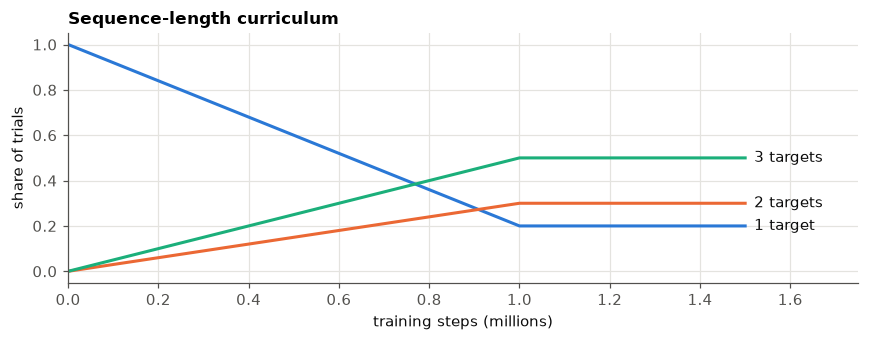

In [18]:
env = BatchedSeqReach1D(Config(), num_envs=1)
steps = np.linspace(0, 1_500_000, 151)
W = np.array([env.curriculum_weights(s) for s in steps])

fig, ax = plt.subplots()
for k, color in enumerate([BLUE, ORANGE, AQUA]):
    ax.plot(steps / 1e6, W[:, k], color=color)
    ax.text(steps[-1] / 1e6 + 0.02, W[-1, k], f"{k + 1} target{'s' if k else ''}",
            color=INK, va="center")
ax.set_xlabel("training steps (millions)")
ax.set_ylabel("share of trials")
ax.set_title("Sequence-length curriculum")
ax.set_xlim(0, 1.75)
plt.tight_layout()

Only training moves this schedule. Any environment built for analysis starts at the final
mixture, so measurements never see the curriculum.

**Where it lives:** `curriculum_weights` in [`seqreach/env.py`](../seqreach/env.py), called
once per iteration from [`seqreach/ppo.py`](../seqreach/ppo.py).

## Check yourself

**1.** You set `plant.tau_act = 0.2`. What changes for the agent, and would planning ahead
matter more or less?

<details><summary>Answer</summary>

Force builds up four times more slowly, so the agent has to start pushing (and braking)
earlier to be at the right place at the right speed. Planning ahead matters **more**: late
decisions can no longer be executed in time.
</details>

**2.** A trial has 3 targets and preview 1. When does the agent first see where T3 is?

<details><summary>Answer</summary>

Only after T2 is hit, when T3 becomes the current target. With preview 1, only the current
target is ever visible.
</details>

**3.** Why does it matter that training mixes preview values across trials?

<details><summary>Answer</summary>

It means one trained agent can be tested with T2 visible and with T2 hidden. Same weights,
same physics, same targets: the only difference is the information. That makes a clean
causal control without training two agents (lesson 4).
</details>

**4.** With `task.dwell_inter = 25`, roughly how fast is the mass moving when it leaves T1?

<details><summary>Answer</summary>

About zero. It must stay within ±0.05 of T1 for 25 steps (0.5 s), which is only possible
by stopping. Lesson 2 shows why this one setting decides whether lookahead is even possible.
</details>

## Summary

- **Everything is in `Config`.** Change it with `cfg.override({"section.key": value})`, or
  `--set section.key=value` on the command line. Each run saves its config.
- **The agent outputs one force every 20 ms.** Force → activation (lagged) → velocity →
  position, so momentum has to be committed in advance.
- **A trial** is: hold until an unpredictable go cue, then hit 1–3 targets in order.
  Intermediate targets are pass-through; the last one must be held for 0.3 s.
- **The loop** is `obs = env.reset(spec)`, then `obs, reward, terminated, truncated, info =
  env.step(force)`, repeated. Training and analysis both use it.
- **The agent sees 16 numbers**, egocentric, and only the targets inside its preview.
  Hiding T2 on the same agent is the core control of lesson 4.

Next: **Lesson 2 · The reward**.